# Fountain calling with one frozen mask and fixed thresholds

Run from top to bottom. Functions live in `fountain_tools/`; plots take a dataset result explicitly.
The supplied WT mask stays linear O/E and unchanged. Every target receives its own O/E expected,
but no new mask, Li threshold, or noise percentile is fitted for that target.

The original notebook is preserved in `archive/fountains-dc-original.ipynb`.
Downstream CTCF/enhancer work is in `fountains-dc-annotations.ipynb`.

**Required external inputs:** your 41 x 41 mask, mm10 view file, and balanced 25 kb maps.
These were referenced by path rather than attached. The 20 manual anchor bins are bundled.


In [1]:
from pathlib import Path
import logging
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Keep this notebook beside fountain_tools/. Change PROJECT_ROOT for your data.
MODULE_ROOT = Path.cwd().resolve()
sys.path.insert(0, str(MODULE_ROOT))
PROJECT_ROOT = MODULE_ROOT  # e.g. Path("/home/irzhe/chromatin_DC/scripts")

from fountain_tools import (
    Settings, Thresholds, FrozenReference, freeze_reference,
    run_dataset, match_manual_peaks, select_examples,
)
from fountain_tools.plots import (
    plot_reference, plot_dense_examples, plot_distributions,
    plot_noise_prominence, plot_fountain_region, compare_counts,
)

logging.getLogger("fontTools").setLevel(logging.WARNING)
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.grid": False,
                     "pdf.fonttype": 42, "ps.fonttype": 42})


## 1. Inputs and target datasets

All maps must use the same assembly, resolution, balancing convention, and frozen view.
Edit only the dataset list to apply the pipeline to another map. Existing untracked snippets
are not silently reused; the new cache has explicit dataset/bin/view provenance.


In [8]:
COOLER_PATHS = {
    'yang2023_dc_CTCFko': '/net/levsha/share/lab/yang2023_dc/results/hic/coolers_library_group/yang2023_dc_CTCFko.mm10.mapq_30.1000.mcool'
}

MASK_PATH = PROJECT_ROOT / "data/WT.coolpuppy.25000.500Kb.mask.npy"
VIEW_PATH = PROJECT_ROOT / "data/mm10.vieframe.tsv"
MANUAL_BED = PROJECT_ROOT / "data/manual_fountains.25kb.bed"
if not MANUAL_BED.exists():
    MANUAL_BED = MODULE_ROOT / "data/manual_fountains.25kb.bed"

OUTPUT_ROOT = PROJECT_ROOT / "results/"
REFERENCE_DIR = PROJECT_ROOT / "results/fountains_fixed/reference_v1"
REFERENCE_JSON = REFERENCE_DIR / "reference.json"
NPROC_EXPECTED = 20

# Start with the original target and one additional map. Edit this list freely.
DATASETS_TO_RUN = ["yang2023_dc_CTCFko"]
ACTIVE_DATASET = DATASETS_TO_RUN[0]


## 2. Freeze the mask and numerical cutoffs once

Cutoffs retained from the uploaded notebook: **FS > 0.5**, **prominence > 0.2206**,
**Scharr <= 80**, and **full-mask finite fraction >= 0.35**.
The printed prominence value was rounded. On FIRST initialization only, the cell below can
recover the full-precision Li threshold from the existing original CTCFko scores, if present.
That recovery uses the old calibration table and never a newly added target.

The 0.35 cutoff retains its old full-mask denominator. `coverage` is a separate diagnostic
using the upper triangle, so complete triangular snippets display 100%, not 50%.
The 50% nonzero filter used later is only for selecting readable example images.

After freezing, change thresholds only by creating a new reference directory.


Using rounded prominence cutoff 0.2206. Enter an exact value here if available.
Frozen reference: 9afbce8520e404a860827dfdeba03270a5a83e318885453c40a88c79cd9de275
Thresholds: Thresholds(min_fs=0.5, min_prominence=0.2206, max_noise=100, min_mask_fraction=0.35, min_nonzero_fraction=0.0)
Prominence precision: None


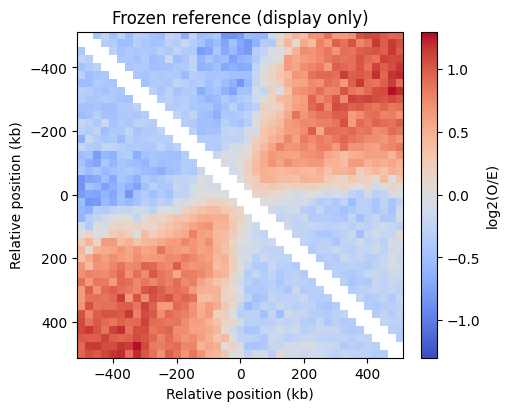

In [10]:
if REFERENCE_JSON.exists():
    reference = FrozenReference.load(REFERENCE_JSON)
else:
    settings = Settings(resolution=25_000, flank=500_000, min_diag=2, assembly="mm10")
    prominence = 0.2206

    RECOVER_EXACT_LI_FROM_OLD_SCORES = True
    CALIBRATION_SCORES_PATH = (
        PROJECT_ROOT / "data/fs_manual_reference/"
        "yang2023_dc_CTCFko.25000.500000.manual_reference.with_noise.scores.tsv"
    )
    if RECOVER_EXACT_LI_FROM_OLD_SCORES and CALIBRATION_SCORES_PATH.exists():
        from skimage.filters import threshold_li
        old = pd.read_csv(CALIBRATION_SCORES_PATH, sep="\t", usecols=["FS_peaks"])
        values = old.loc[np.isfinite(old.FS_peaks) & old.FS_peaks.ge(0), "FS_peaks"].to_numpy()
        if len(np.unique(values)) < 2:
            raise ValueError("The original calibration table has no varying finite prominences.")
        prominence = float(threshold_li(values))
        note = f"Li recovered once from existing calibration scores: {CALIBRATION_SCORES_PATH}"
    else:
        print("Using rounded prominence cutoff 0.2206. Enter an exact value here if available.")

    thresholds = Thresholds(
        min_fs=0.5, min_prominence=prominence, max_noise=100,
        min_mask_fraction=0.35, min_nonzero_fraction=0.0,
    )
    reference = freeze_reference(
        MASK_PATH, VIEW_PATH, REFERENCE_DIR,
        settings=settings, thresholds=thresholds, mask_scale="linear_OE",
        calibration_dataset="yang2023_dc_CTCFko", prominence_note=None,
    )

print("Frozen reference:", reference.metadata["reference_id"])
print("Thresholds:", reference.thresholds)
print("Prominence precision:", reference.metadata["prominence_note"])
fig = plot_reference(reference)
plt.show()


## 3. Score every requested map with the same frozen reference

Each map gets its own balanced, unsmoothed expected contacts. Snippets are streamed to disk
in cooler-bin order. FS is Pearson(saved mask, linear O/E), and Scharr is calculated from the
full linear snippet. Peak prominence is evaluated within contiguous finite runs and view regions.

This step may take several minutes and about 1.4 GiB of snippet storage per 109,033-bin map.
Compatible reruns reuse the cache. File/weight/view/mask changes trigger a clear error rather
than silently mixing inputs. The original notebook's outputs are not overwritten.


In [11]:
results = {}
for label in DATASETS_TO_RUN:
    if label not in COOLER_PATHS:
        raise KeyError(f"Add a path for {label!r} to COOLER_PATHS.")
    results[label] = run_dataset(
        label, COOLER_PATHS[label], reference,
        output_root=OUTPUT_ROOT, nproc=NPROC_EXPECTED,
    )

comparison = compare_counts(results)
display(comparison)
comparison.to_csv(OUTPUT_ROOT / "dataset_comparison.tsv", sep="\t", index=False)
assert comparison["reference_id"].nunique() == 1

active = results[ACTIVE_DATASET]
display(active.summary)
display(active.calls.groupby("chrom", observed=True).size().rename("n_candidates"))


Calculating expected contacts for /net/levsha/share/lab/yang2023_dc/results/hic/coolers_library_group/yang2023_dc_CTCFko.mm10.mapq_30.1000.mcool::/resolutions/25000


INFO:root:creating a Pool of 20 workers


  chr1: 7,778 complete windows
  chr2: 7,244 complete windows
  chr3: 6,361 complete windows
  chr4: 6,220 complete windows
  chr5: 6,033 complete windows
  chr6: 5,949 complete windows
  chr7: 5,777 complete windows
  chr8: 5,136 complete windows
  chr9: 4,943 complete windows
  chr10: 5,187 complete windows
  chr11: 4,843 complete windows
  chr12: 4,765 complete windows
  chr13: 4,776 complete windows
  chr14: 4,956 complete windows
  chr15: 4,121 complete windows
  chr16: 3,888 complete windows
  chr17: 3,759 complete windows
  chr18: 3,588 complete windows
  chr19: 2,417 complete windows
  chrX: 6,801 complete windows
Calculating FS, pixel coverage, and Scharr noise...
               stage  n_candidates
  All local FS peaks         10274
Pixel-quality cutoff          9578
           FS cutoff           907
   Prominence cutoff           776
        Noise cutoff           776


,dataset,eligible_scored_bins,n_calls,calls_per_1000_eligible_bins,reference_id
0,yang2023_dc_CTCFko,97002,776,7.999835,9afbce8520e404a860827dfdeba03270a5a83e31888545...


,stage,n_candidates
0,All local FS peaks,10274
1,Pixel-quality cutoff,9578
2,FS cutoff,907
3,Prominence cutoff,776
4,Noise cutoff,776


chrom
chr1     64
chr10    40
chr11    45
chr12    32
chr13    38
chr14    28
chr15    32
chr16    23
chr17    33
chr18    27
chr19    18
chr2     59
chr3     45
chr4     53
chr5     44
chr6     46
chr7     37
chr8     43
chr9     47
chrX     22
Name: n_candidates, dtype: int64

## 4. Match manual bases to nearest local peaks

Matching uses a fixed +/-50 kb tolerance, independent of score magnitude and thresholds.
Unmatched annotations remain visible. Multiple annotations can share a peak; plots count that
peak once. These manual sites constructed the WT reference, so they are training examples,
not an independent validation set. They are not used as truth labels for SMC peaks.


In [12]:
manual_matches = match_manual_peaks(
    active.scores, MANUAL_BED,
    resolution=reference.settings.resolution, max_distance=50_000,
)
manual_matches.to_csv(active.directory / "manual_peak_matches.tsv", sep="\t", index=False)
display(manual_matches)
print("Matched annotations:", int(manual_matches.matched.sum()), "/", len(manual_matches))


,chrom,manual_start,manual_center,matched,peak_start,peak_end,distance_bp,offset_bp,FS,FS_peaks,Scharr_box,shared_peak
0,chr4,75250000,75262500.0,True,75275000.0,75300000.0,25000.0,25000.0,0.827072,1.233595,41.174748,False
1,chr4,74300000,74312500.0,True,74250000.0,74275000.0,50000.0,-50000.0,0.442907,0.715928,28.240130,False
2,chr4,80275000,80287500.0,True,80250000.0,80275000.0,25000.0,-25000.0,0.622460,0.808795,34.123003,False
3,chr4,84975000,84987500.0,True,84950000.0,84975000.0,25000.0,-25000.0,0.744238,1.066943,28.362553,False
4,chr4,93450000,93462500.0,True,93450000.0,93475000.0,0.0,0.0,0.828615,1.463788,62.363305,False
5,chr4,97775000,97787500.0,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
6,chr5,12925000,12937500.0,True,12900000.0,12925000.0,25000.0,-25000.0,0.727720,0.989949,43.261840,False
7,chr5,17925000,17937500.0,True,17900000.0,17925000.0,25000.0,-25000.0,0.796083,1.136862,43.047982,False
8,chr5,27150000,27162500.0,True,27150000.0,27175000.0,0.0,0.0,0.838704,1.517495,30.010864,False
9,chr5,47450000,47462500.0,True,47425000.0,47450000.0,25000.0,-25000.0,0.658879,1.201370,35.282031,False


Matched annotations: 19 / 20


## 5. Distributions and thresholds

Histograms show per-group probability mass, not the probability of a genuine fountain.
The lines always come from the frozen reference. No plotting cell recalculates a threshold.


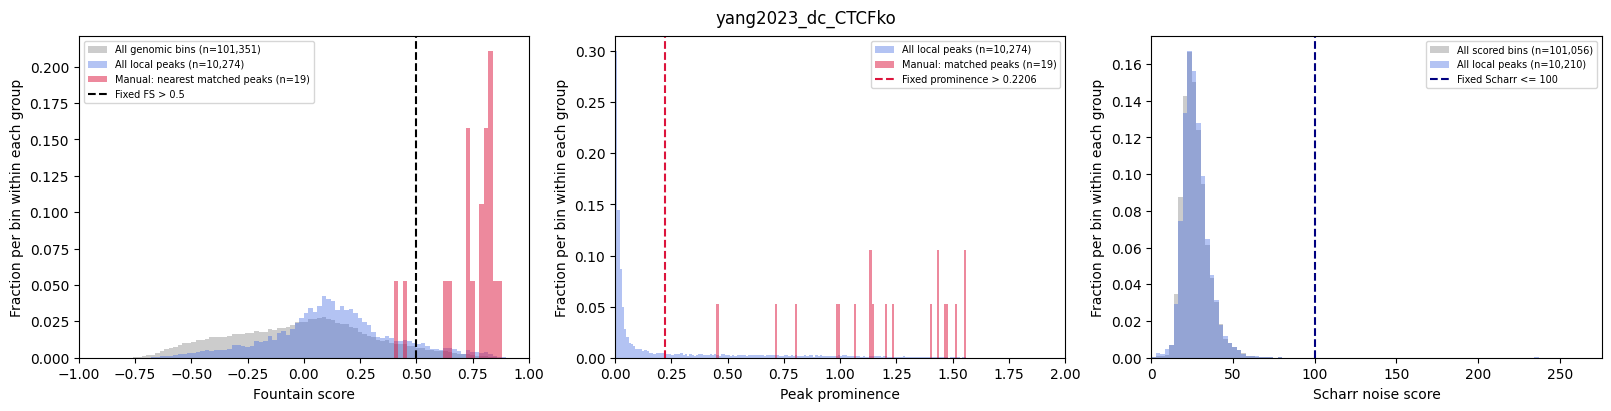

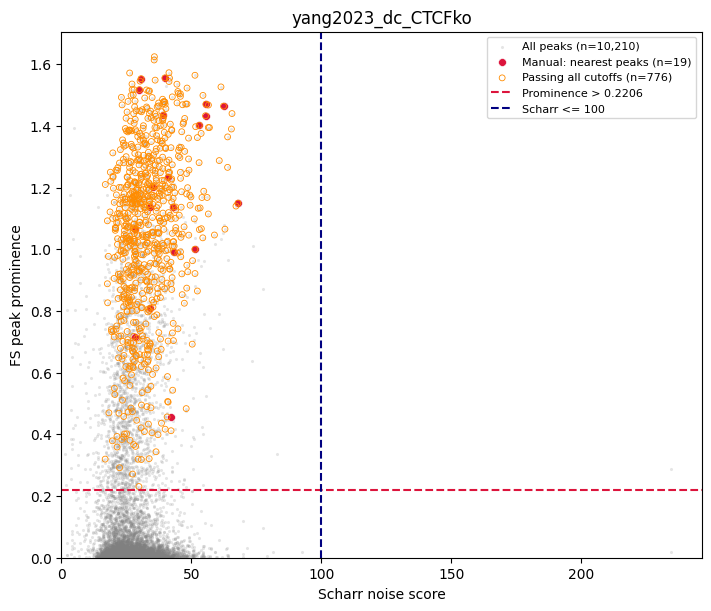

In [13]:
fig = plot_distributions(active, manual_matches)
plt.show()
fig = plot_noise_prominence(active, manual_matches)
plt.show()


## 6. Browse filtered calls in a dense grid

The saved call set includes every local peak passing the fixed call cutoffs. The example grid
can additionally exclude sparse windows and space images apart. These viewing filters do not
change `active.calls` or its exported BED. Change `limit=None` to show all selected examples.


Showing 120 of 776 passing calls


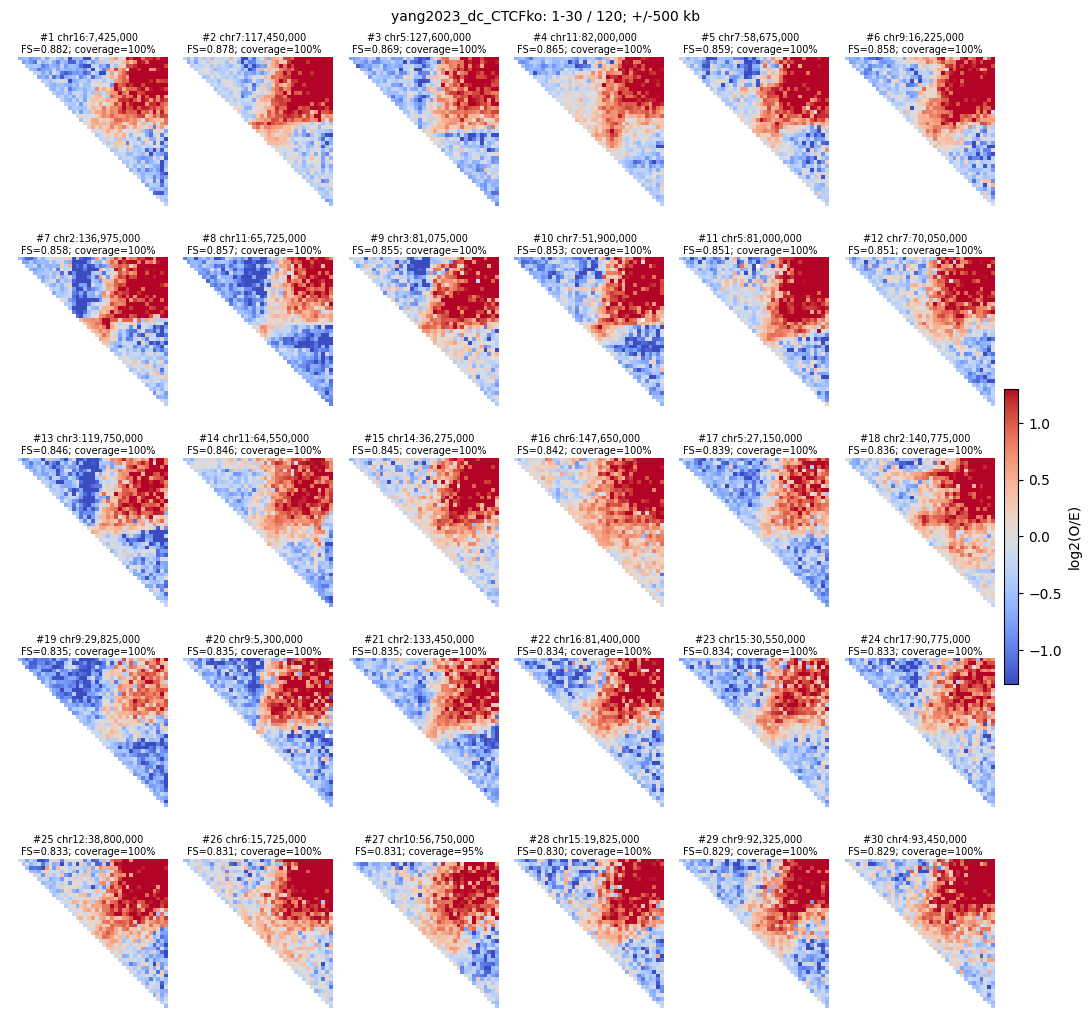

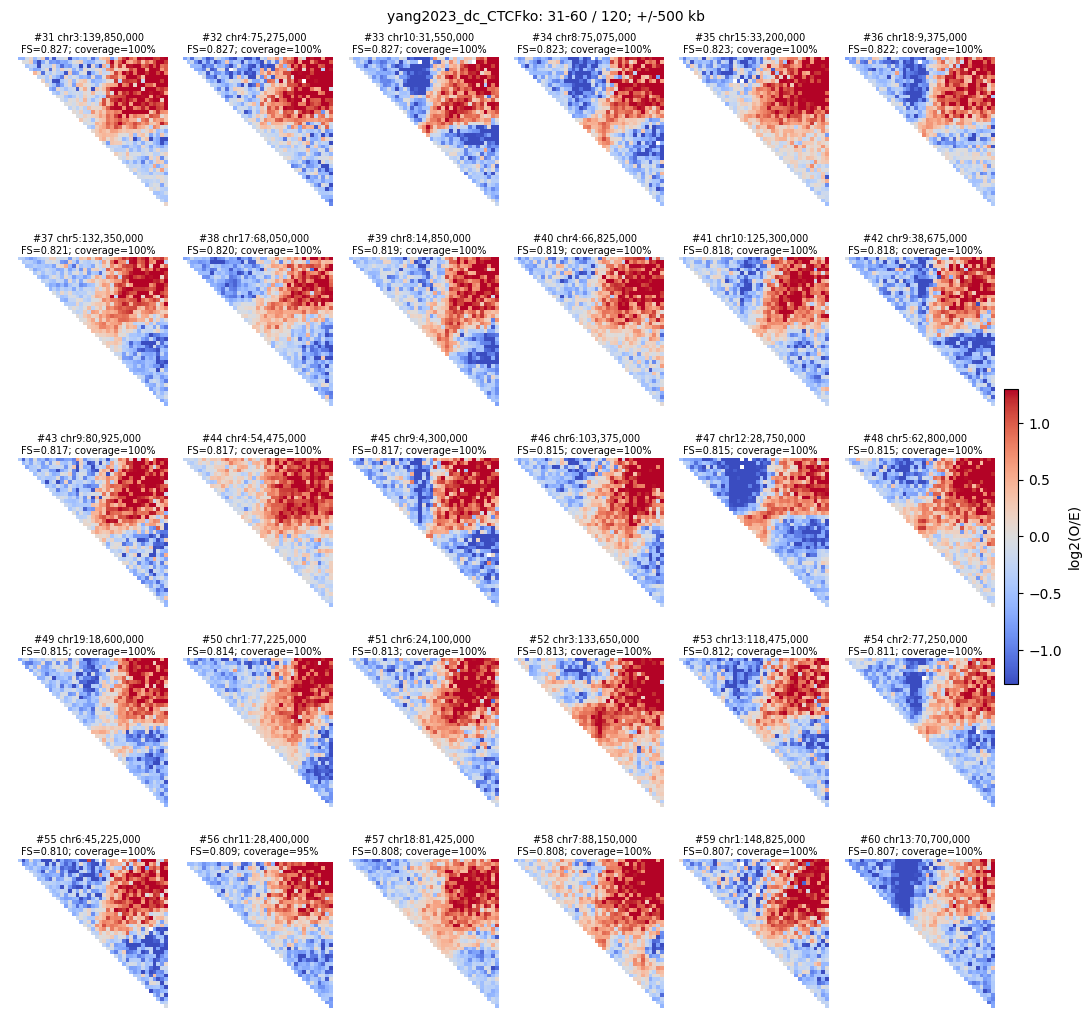

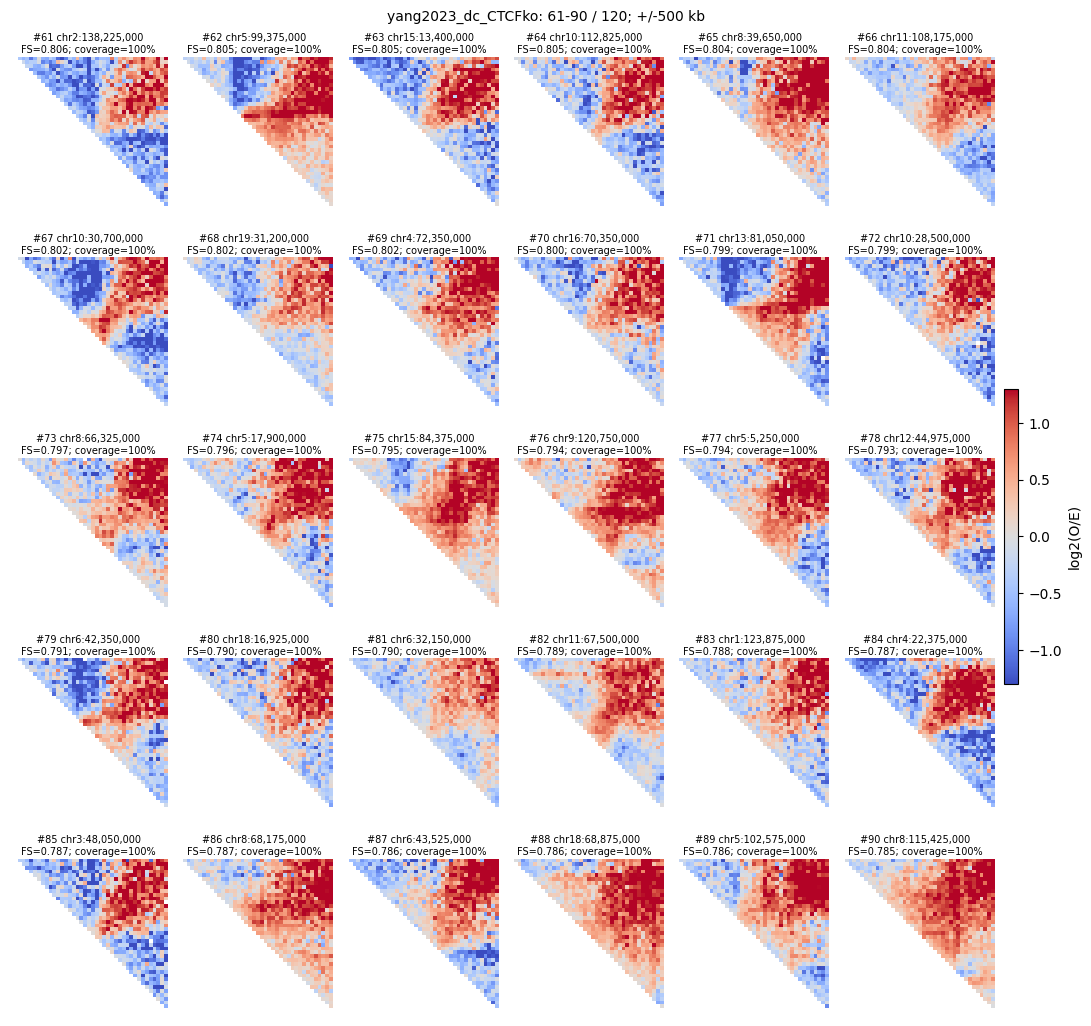

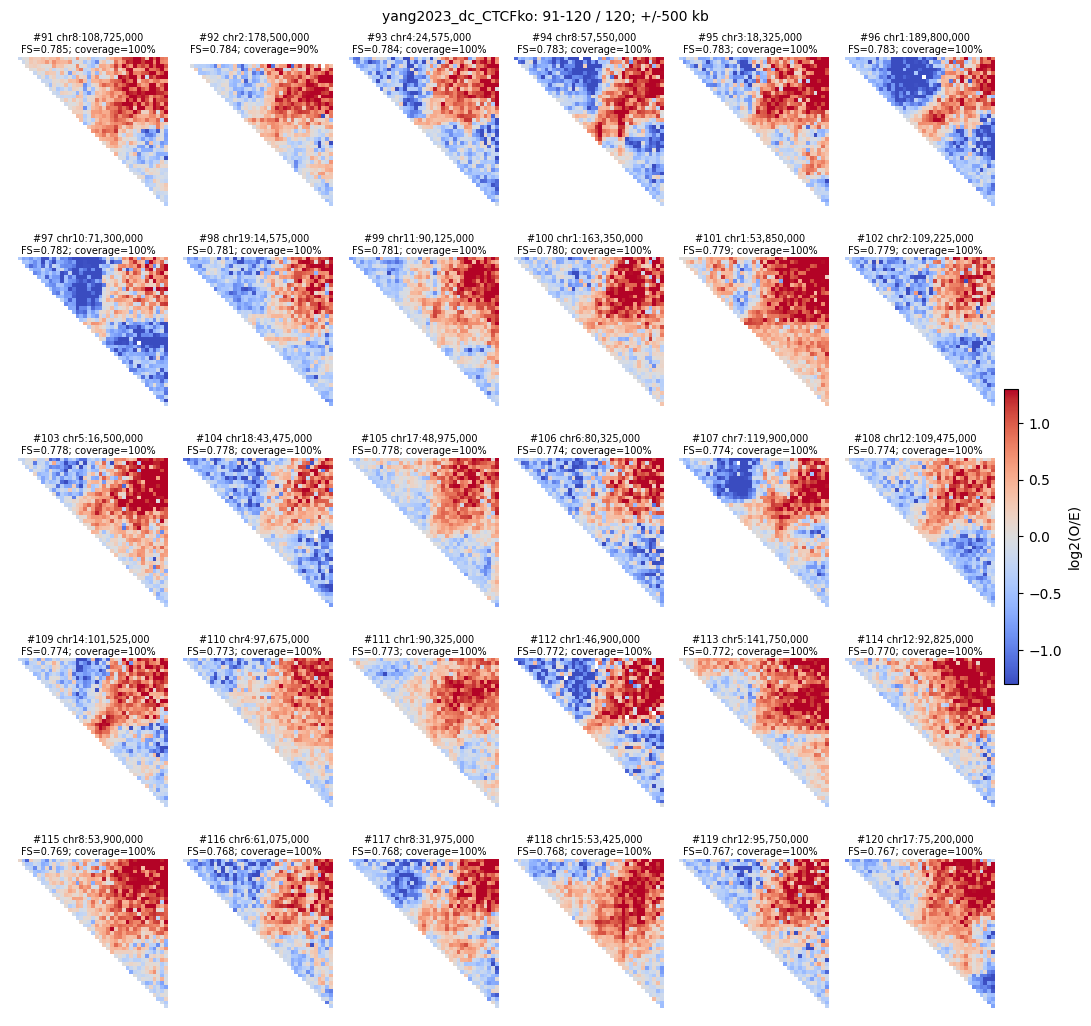

In [14]:
examples = select_examples(
    active.calls, n=120, min_separation=0,
    min_coverage=0.50, min_nonzero_fraction=0.50,
)
print(f"Showing {len(examples)} of {len(active.calls)} passing calls")
plot_dense_examples(active, examples, ncols=6, per_figure=30, panel_size=1.8, limit=None)


### Optional: independent examples away from manual windows

Use an exclusion radius of 1 Mb and 1 Mb spacing to avoid overlapping reference windows.
These are high-scoring candidates, not independently confirmed fountains.


In [15]:
RUN_OUTSIDE_MANUAL_GRID = False
if RUN_OUTSIDE_MANUAL_GRID:
    outside_examples = select_examples(
        active.calls, n=120, min_separation=1_000_000,
        manual=MANUAL_BED, exclusion_radius=1_000_000,
        min_coverage=0.5, min_nonzero_fraction=0.5,
    )
    plot_dense_examples(active, outside_examples, limit=None)


## 7. Contact map, FS, and Scharr tracks

The map displays balanced contacts. FS was calculated from O/E snippets. The rotated geometry
uses aspect 0.5. Gray/red triangles distinguish prominence below/above the fixed cutoff; orange
circles and dashed guides mark calls passing all cutoffs. The Scharr panel shows its fixed cutoff.
Color limits are shared parameters, not target-specific normalization.


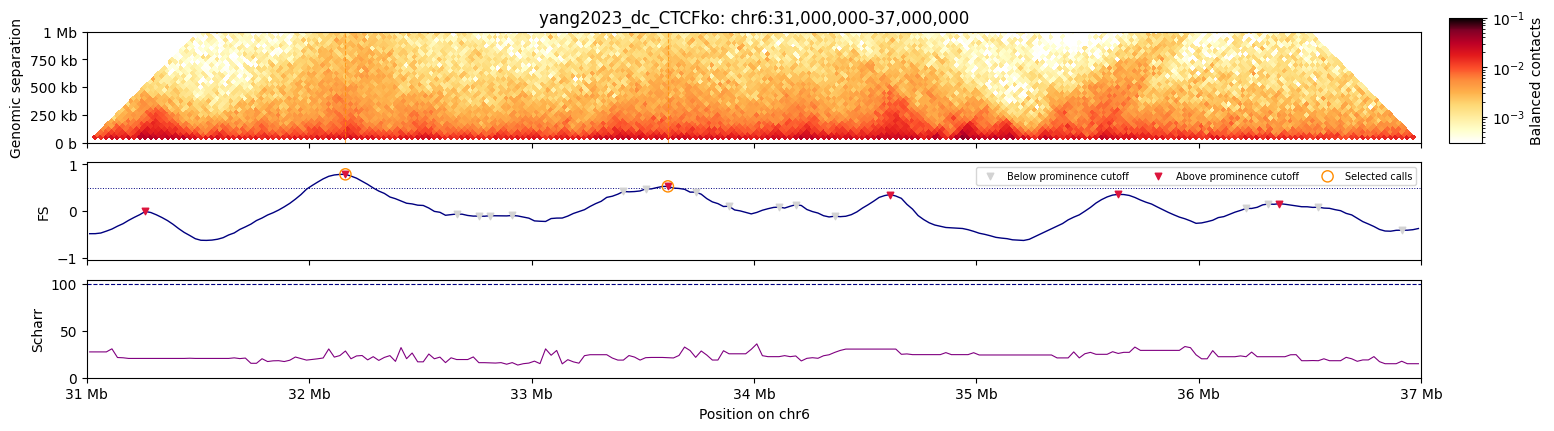

In [16]:
fig = plot_fountain_region(
    active, ("chr6", 31_000_000, 37_000_000),
    max_distance=1_000_000, vmin=0.0003, vmax=0.1,
)
plt.show()


In [13]:
RUN_MAP_EXAMPLES = False
if RUN_MAP_EXAMPLES:
    for row in active.calls.nlargest(10, "FS").itertuples(index=False):
        center = int(row.center)
        fig = plot_fountain_region(
            active, (row.chrom, center-1_500_000, center+1_500_000),
            max_distance=1_000_000,
        )
        plt.show()
        plt.close(fig)


## 8. Apply to one more map later

Use the SAME reference JSON, and a new dataset label. The only new normalization is that map's
expected contacts. Keep assembly/resolution/weights/view consistent. Identical cutoffs do not
guarantee identical sensitivity across sequencing depths, so inspect coverage and distributions.


In [14]:
RUN_ADDITIONAL_MAP = False
if RUN_ADDITIONAL_MAP:
    other = run_dataset(
        "yang2023_dc_WT_LPS", COOLER_PATHS["yang2023_dc_WT_LPS"],
        FrozenReference.load(REFERENCE_JSON),
        output_root=OUTPUT_ROOT, nproc=NPROC_EXPECTED,
    )
    display(other.summary)
    fig = plot_noise_prominence(other)
    plt.show()
    plot_dense_examples(other, limit=120)


## 9. Dataset-specific exports

Outputs were written by `run_dataset`; there is no separate stale `df_strongest` export.
`calls.tsv` / `calls.bed` are threshold-filtered candidates. Display spacing and manual exclusion
are not applied to these exports. Each run also stores the frozen mask identity, thresholds,
source/expected/cache identity, package versions, and filter counts.


In [ ]:
for label, result in results.items():
    print(label)
    for filename in ["scores.tsv.gz", "calls.tsv", "calls.bed", "filter_counts.tsv", "run.json"]:
        print(" ", result.directory / filename)
